# Logistic Regression: Student Placement Prediction

This notebook introduces **binary classification** by predicting whether an engineering student is **Placed** or **Not Placed** from daily study hours.

## Learning objectives

By the end, you should be able to:

1. distinguish classification from regression;
2. prepare features (`X`) and a target (`y`);
3. create reproducible training and test sets;
4. train and interpret a logistic regression model;
5. evaluate classification models with suitable metrics; and
6. compare Logistic Regression, Decision Tree, and Support Vector Machine (SVM).

> Run the cells from top to bottom. Each cell depends on variables created earlier.

In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [6]:
# Build paths relative to this notebook so the project can be moved safely.
DATA_DIR = Path.cwd().parent / "linear_regression_project" / "raw_data"

features = pd.read_csv(DATA_DIR / "indian_engineering_student_placement.csv")
targets = pd.read_csv(DATA_DIR / "placement_targets.csv")

# Join by Student_ID instead of assuming both files have the same row order.
data = features.merge(
    targets[["Student_ID", "placement_status"]],
    on="Student_ID",
    validate="one_to_one",
)

print(f"Rows: {data.shape[0]:,}")
print(f"Columns: {data.shape[1]}")

Rows: 5,000
Columns: 24


## 1. Understand the data

The information is stored in two CSV files:

- the **feature file** contains student characteristics such as CGPA and study hours;
- the **target file** contains the outcome we want to predict: `placement_status`.

`Student_ID` is the common key used to combine them. It identifies a student; it is not useful as a predictive feature.

In [7]:
display(data.head())

print("Column data types:")
display(data.dtypes.to_frame("data_type"))

,Student_ID,gender,branch,cgpa,tenth_percentage,twelfth_percentage,backlogs,study_hours_per_day,attendance_percentage,projects_completed,internships_completed,coding_skill_rating,communication_skill_rating,aptitude_skill_rating,hackathons_participated,certifications_count,sleep_hours,stress_level,part_time_job,family_income_level,city_tier,internet_access,extracurricular_involvement,placement_status
0,1,Male,ECE,8.74,74.0,75.0,0,3.8,71.1,7,3,4,2,5,4,5,6.5,8,Yes,Medium,Tier 2,Yes,Medium,Placed
1,2,Female,ECE,7.80,75.3,69.7,0,6.3,69.5,5,1,3,4,3,4,1,7.1,8,Yes,Medium,Tier 3,Yes,Low,Placed
2,3,Female,IT,6.95,62.8,68.3,0,1.5,62.5,8,2,5,1,4,6,3,6.1,2,No,Low,Tier 2,Yes,High,Placed
3,4,Male,ECE,7.46,57.9,51.4,1,4.7,64.6,6,2,3,1,4,2,2,7.3,7,No,Medium,Tier 1,Yes,Low,Placed
4,5,Male,IT,6.86,61.3,73.5,2,5.2,75.9,3,3,2,5,3,2,1,6.0,7,No,Medium,Tier 1,Yes,Medium,Placed


Column data types:


,data_type
Student_ID,int64
gender,object
branch,object
cgpa,float64
tenth_percentage,float64
twelfth_percentage,float64
backlogs,int64
study_hours_per_day,float64
attendance_percentage,float64
projects_completed,int64


In [8]:
missing_values = data.isna().sum()
print("Duplicate Student_ID values:", data["Student_ID"].duplicated().sum())
print("Total missing values:", missing_values.sum())

display(data[["study_hours_per_day", "placement_status"]].describe(include="all"))

Duplicate Student_ID values: 0
Total missing values: 1006


,study_hours_per_day,placement_status
count,5000.000000,5000
unique,NaN,2
top,NaN,Placed
freq,NaN,4303
mean,4.041120,NaN
std,1.967754,NaN
min,0.000000,NaN
25%,2.700000,NaN
50%,4.000000,NaN
75%,5.400000,NaN


## 2. Explore the target and feature

This is a **binary classification** problem because the target has two categories: `Placed` and `Not Placed`.

We begin with only `study_hours_per_day`. A one-feature model is not intended to represent every cause of placement; it is used because its behavior can be plotted and understood easily.

Before training, check whether one target class is much larger than the other. This is called **class imbalance**.

Class counts:


,students
placement_status,
Placed,4303
Not Placed,697


Class percentages:


,percent
placement_status,
Placed,86.1
Not Placed,13.9


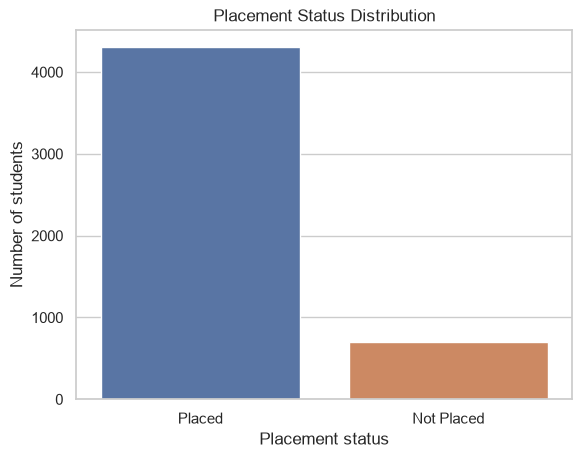

In [9]:
class_counts = data["placement_status"].value_counts()
class_percentages = data["placement_status"].value_counts(normalize=True).mul(100).round(1)

print("Class counts:")
display(class_counts.to_frame("students"))
print("Class percentages:")
display(class_percentages.to_frame("percent"))

sns.countplot(data=data, x="placement_status", hue="placement_status", legend=False)
plt.title("Placement Status Distribution")
plt.xlabel("Placement status")
plt.ylabel("Number of students")
plt.show()

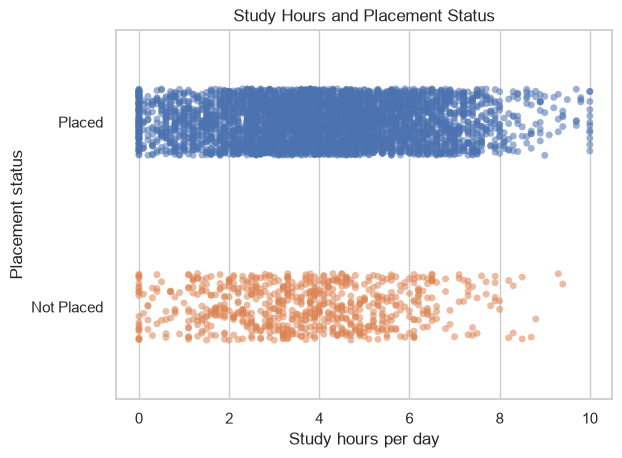

In [10]:
sns.stripplot(
    data=data,
    x="study_hours_per_day",
    y="placement_status",
    hue="placement_status",
    jitter=0.18,
    alpha=0.55,
    legend=False,
)
plt.title("Study Hours and Placement Status")
plt.xlabel("Study hours per day")
plt.ylabel("Placement status")
plt.show()

## 3. Prepare `X` and `y`

Machine-learning notation commonly uses:

- **`X`** for the input feature table. It stays two-dimensional, even with one feature.
- **`y`** for the target labels the model must learn to predict.

We keep the original text labels throughout the notebook. Mixing numeric labels (`0`, `1`) with text predictions (`Placed`, `Not Placed`) would make evaluation incorrect.

In [11]:
X = data[["study_hours_per_day"]]
y = data["placement_status"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Target labels:", sorted(y.unique()))

X shape: (5000, 1)
y shape: (5000,)
Target labels: ['Not Placed', 'Placed']


## 4. Split the data

The model learns patterns from the **training set**. The untouched **test set** estimates how well those patterns generalize to new students.

- `test_size=0.25` reserves 25% of rows for testing.
- `random_state=42` makes the split reproducible.
- `stratify=y` keeps approximately the same class ratio in both sets.

Never train on the test set: that would cause **data leakage** and produce misleading scores.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y,
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).round(3))
print("Test class proportions:")
display(y_test.value_counts(normalize=True).round(3))

Training rows: 3750
Test rows: 1250

Training class proportions:


placement_status
Placed        0.861
Not Placed    0.139
Name: proportion, dtype: float64

Test class proportions:


placement_status
Placed        0.861
Not Placed    0.139
Name: proportion, dtype: float64

## 5. Logistic regression

Despite its name, logistic regression is a **classification algorithm**. It first calculates a linear score:

$$z = b_0 + b_1x$$

It then uses the sigmoid function to convert that score into a probability between 0 and 1:

$$P(\text{Placed}) = \frac{1}{1 + e^{-z}}$$

A probability at or above the decision threshold is assigned to one class; a lower probability is assigned to the other. `class_weight="balanced"` gives more influence to the less frequent class during training.

In [13]:
logistic_model = LogisticRegression(
    class_weight="balanced",
    solver="liblinear",
    random_state=42,
)
logistic_model.fit(X_train, y_train)

print("Classes:", logistic_model.classes_)
print("Intercept (b0):", logistic_model.intercept_[0].round(4))
print("Study-hours coefficient (b1):", logistic_model.coef_[0, 0].round(4))

Classes: ['Not Placed' 'Placed']
Intercept (b0): -0.3958
Study-hours coefficient (b1): 0.1023


### Interpret the coefficient

The coefficient tells us the direction of the relationship:

- a **positive** coefficient means more study hours increase the model's estimated probability of placement;
- a **negative** coefficient means more study hours decrease that probability;
- a value near zero means this feature has little effect in the fitted model.

This is an association learned from the dataset, not proof that study hours alone cause placement.

In [14]:
predictions = logistic_model.predict(X_test)
probabilities = logistic_model.predict_proba(X_test)

placed_index = np.where(logistic_model.classes_ == "Placed")[0][0]
prediction_table = X_test.copy()
prediction_table["actual"] = y_test
prediction_table["predicted"] = predictions
prediction_table["probability_placed"] = probabilities[:, placed_index].round(3)

display(prediction_table.head(10))

,study_hours_per_day,actual,predicted,probability_placed
4613,3.4,Placed,Not Placed,0.488
3360,5.6,Not Placed,Placed,0.544
731,2.1,Not Placed,Not Placed,0.455
989,1.5,Placed,Not Placed,0.440
3867,4.8,Placed,Placed,0.524
1781,5.2,Not Placed,Placed,0.534
937,3.6,Placed,Not Placed,0.493
2473,6.8,Not Placed,Placed,0.574
1269,2.8,Placed,Not Placed,0.473
1666,5.6,Placed,Placed,0.544


In [15]:
def evaluate_model(model_name, y_true, y_pred):
    """Return the most common binary-classification metrics."""
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, pos_label="Placed", zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, pos_label="Placed", zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, y_pred, pos_label="Placed", zero_division=0
        ),
    }

## 6. Evaluate the classifier

A **confusion matrix** counts four outcomes:

- **True Positive:** predicted Placed, actually Placed
- **True Negative:** predicted Not Placed, actually Not Placed
- **False Positive:** predicted Placed, actually Not Placed
- **False Negative:** predicted Not Placed, actually Placed

Useful metrics:

- **Accuracy:** fraction of all predictions that are correct
- **Precision:** among predicted placements, fraction actually placed
- **Recall:** among actually placed students, fraction found by the model
- **F1 score:** balance between precision and recall

Accuracy alone can be misleading when classes are imbalanced.

,Accuracy,Precision,Recall,F1 Score
Model,,,,
Logistic Regression,0.546,0.877,0.55,0.676


              precision    recall  f1-score   support

  Not Placed       0.16      0.52      0.24       174
      Placed       0.88      0.55      0.68      1076

    accuracy                           0.55      1250
   macro avg       0.52      0.54      0.46      1250
weighted avg       0.78      0.55      0.62      1250



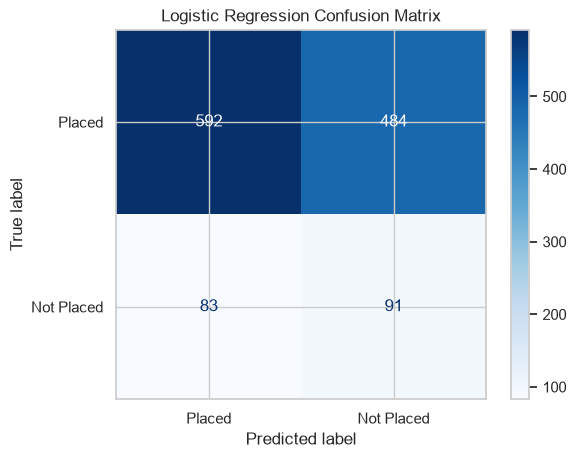

In [16]:
logistic_results = pd.DataFrame(
    [evaluate_model("Logistic Regression", y_test, predictions)]
).set_index("Model")

display(logistic_results.round(3))
print(classification_report(y_test, predictions, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    labels=["Placed", "Not Placed"],
    cmap="Blues",
)
plt.title("Logistic Regression Confusion Matrix")
plt.show()

## 7. Visualize the probability curve

The red sigmoid curve shows the model's estimated probability of `Placed` for each possible number of study hours. The dashed line is the usual probability threshold of 0.5.

Because scikit-learn stores class probabilities in the order shown by `model.classes_`, the code finds the `Placed` column instead of assuming its position.

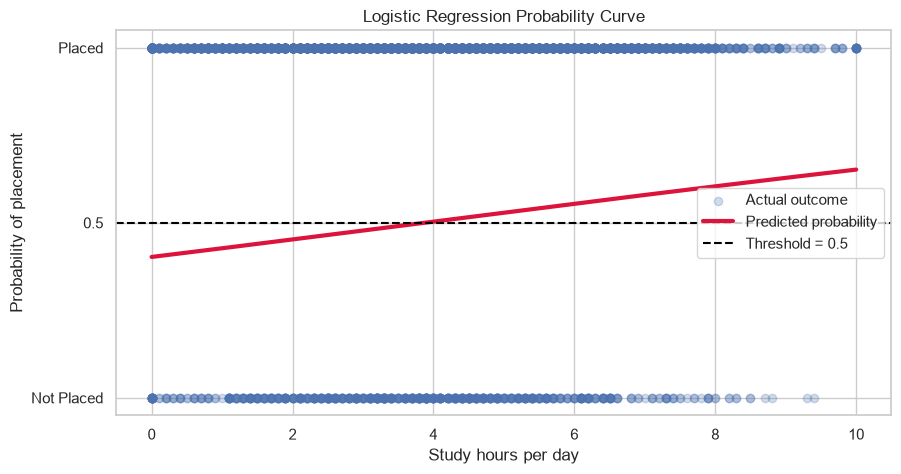

In [17]:
hours_grid = np.linspace(
    data["study_hours_per_day"].min(),
    data["study_hours_per_day"].max(),
    300,
)
hours_grid_frame = pd.DataFrame({"study_hours_per_day": hours_grid})
placed_probability = logistic_model.predict_proba(hours_grid_frame)[:, placed_index]
actual_numeric = (y == "Placed").astype(int)

plt.figure(figsize=(10, 5))
plt.scatter(
    data["study_hours_per_day"],
    actual_numeric,
    alpha=0.25,
    label="Actual outcome",
)
plt.plot(hours_grid, placed_probability, color="crimson", linewidth=3, label="Predicted probability")
plt.axhline(0.5, color="black", linestyle="--", label="Threshold = 0.5")
plt.xlabel("Study hours per day")
plt.ylabel("Probability of placement")
plt.yticks([0, 0.5, 1], ["Not Placed", "0.5", "Placed"])
plt.title("Logistic Regression Probability Curve")
plt.legend()
plt.show()

In [18]:
study_hours = 3.0
new_student = pd.DataFrame({"study_hours_per_day": [study_hours]})
new_prediction = logistic_model.predict(new_student)[0]
new_probability = logistic_model.predict_proba(new_student)[0, placed_index]

print(f"Study hours per day: {study_hours}")
print(f"Predicted class: {new_prediction}")
print(f"Probability of placement: {new_probability:.1%}")

Study hours per day: 3.0
Predicted class: Not Placed
Probability of placement: 47.8%


## 8. Decision Tree and SVM

We will now compare Logistic Regression with two other classification algorithms. All models use the **same feature**, **same training rows**, and **same test rows**, making their scores directly comparable.

### 8.1 Decision Tree Classifier

A Decision Tree makes predictions by asking a sequence of yes/no questions. With this dataset, a question might look like:

> Is `study_hours_per_day <= 4.2`?

Each question splits the data into smaller groups:

- the top box is the **root node**;
- boxes containing questions are **decision nodes**;
- final boxes containing predictions are **leaf nodes**.

We use `criterion="entropy"` to measure how mixed the classes are in a node. The tree chooses splits that reduce this mixture. `max_depth=4` limits the number of levels and helps control **overfitting**, where a model memorizes training examples but performs poorly on unseen data.

**Strengths:** easy to visualize, handles nonlinear rules, and requires no feature scaling.

**Limitations:** a deep tree can overfit, and small data changes can produce a different tree.

### 8.2 Support Vector Machine (SVM)

An SVM tries to create a decision boundary that separates the classes. It prefers the boundary with the largest possible **margin**, meaning the widest gap between the nearest examples from each class. Those nearest examples are called **support vectors** because they determine the boundary.

`SVC` uses the **RBF kernel** by default. A kernel allows the model to learn a curved, nonlinear boundary instead of only a straight line. `class_weight="balanced"` gives additional importance to the less frequent class.

**Strengths:** can learn complex boundaries and often performs well on medium-sized datasets.

**Limitations:** less interpretable than Logistic Regression or a small Decision Tree, sensitive to feature scale, and slower on very large datasets.

> This lesson uses one feature, so scaling does not materially change its relative ordering. With multiple features measured in different units, scale them before training SVM.

In [19]:
decision_tree = DecisionTreeClassifier(
    max_depth=4,
    criterion="entropy",
    class_weight="balanced",
    random_state=42,
)
svc_model = SVC(class_weight="balanced")

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree,
    "SVM": svc_model,
}

results = []
model_predictions = {}

for model_name, model in models.items():
    model.fit(X_train, y_train)
    current_predictions = model.predict(X_test)
    model_predictions[model_name] = current_predictions

    model_result = evaluate_model(model_name, y_test, current_predictions)
    model_result["Train Accuracy"] = model.score(X_train, y_train)
    model_result["Generalization Gap"] = (
        model_result["Train Accuracy"] - model_result["Accuracy"]
    )
    results.append(model_result)

,Train Accuracy,Accuracy,Precision,Recall,F1 Score,Generalization Gap
Model,,,,,,
Logistic Regression,0.535,0.546,0.877,0.550,0.676,-0.011
Decision Tree,0.485,0.482,0.880,0.462,0.606,0.003
SVM,0.469,0.482,0.884,0.459,0.604,-0.014


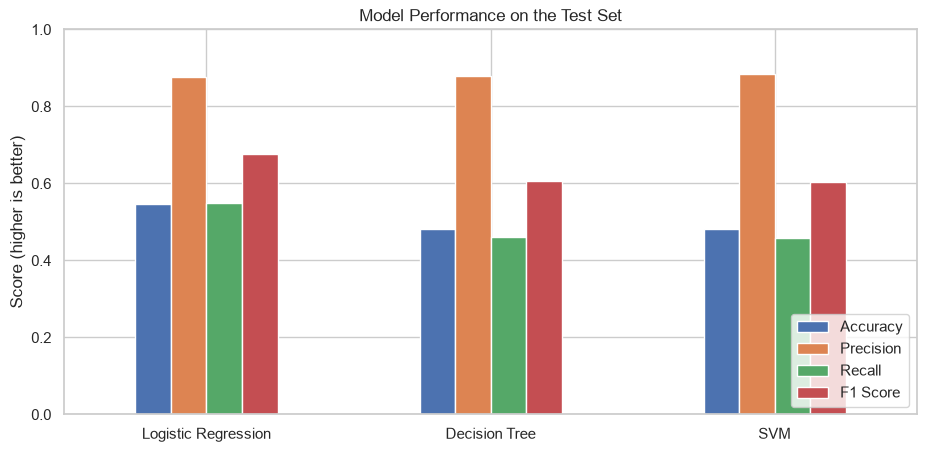

Highest F1 score: Logistic Regression (0.676)
Smallest train-test gap: Decision Tree (0.003)


In [20]:
comparison = pd.DataFrame(results).set_index("Model")
comparison = comparison[
    ["Train Accuracy", "Accuracy", "Precision", "Recall", "F1 Score", "Generalization Gap"]
].round(3)

display(comparison.sort_values("F1 Score", ascending=False))

metric_columns = ["Accuracy", "Precision", "Recall", "F1 Score"]
comparison[metric_columns].plot(kind="bar", ylim=(0, 1), figsize=(11, 5))
plt.title("Model Performance on the Test Set")
plt.ylabel("Score (higher is better)")
plt.xlabel("")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

best_f1_model = comparison["F1 Score"].idxmax()
smallest_gap_model = comparison["Generalization Gap"].abs().idxmin()

print(f"Highest F1 score: {best_f1_model} ({comparison.loc[best_f1_model, 'F1 Score']:.3f})")
print(
    f"Smallest train-test gap: {smallest_gap_model} "
    f"({comparison.loc[smallest_gap_model, 'Generalization Gap']:.3f})"
)

### How to compare the output

Read the table one column at a time:

- **Train Accuracy** shows performance on examples the model already saw.
- **Accuracy** shows the percentage of unseen test examples classified correctly.
- **Precision** answers: “When the model predicts Placed, how often is it correct?”
- **Recall** answers: “Of all students who were actually Placed, how many did the model find?”
- **F1 Score** balances precision and recall; it is useful when both mistakes matter.
- **Generalization Gap** is train accuracy minus test accuracy. A large positive gap is a warning sign for overfitting.

Do not choose a model from one score alone. For example, a placement-support system may prioritize recall if missing a student who needs support is costly, while another application may prioritize precision.

### What these results mean

With the fixed split used in this notebook:

| Model | Accuracy | Precision | Recall | F1 Score |
|---|---:|---:|---:|---:|
| Logistic Regression | 0.546 | 0.877 | 0.550 | 0.676 |
| Decision Tree | 0.482 | 0.880 | 0.462 | 0.606 |
| SVM | 0.482 | 0.884 | 0.459 | 0.604 |

**Logistic Regression performs best overall here.** Its F1 score is highest because it finds more of the actually placed students while maintaining high precision.

**SVM has the highest precision**, but only by a very small amount. Its lower recall means it misses more students who were actually placed.

**Decision Tree and SVM have equal accuracy**, yet their precision, recall, and F1 scores differ slightly. This demonstrates why accuracy alone is not enough for comparing classifiers.

The three models agree on 1,003 of the 1,250 test examples and disagree on 247. This disagreement shows that model choice affects individual predictions even when overall scores look similar.

None of the accuracy scores is especially high. That is an important result, not a failure: `study_hours_per_day` alone does not contain enough information to predict placement reliably. Adding meaningful features such as CGPA, coding skill, communication skill, projects, and internships may improve performance.

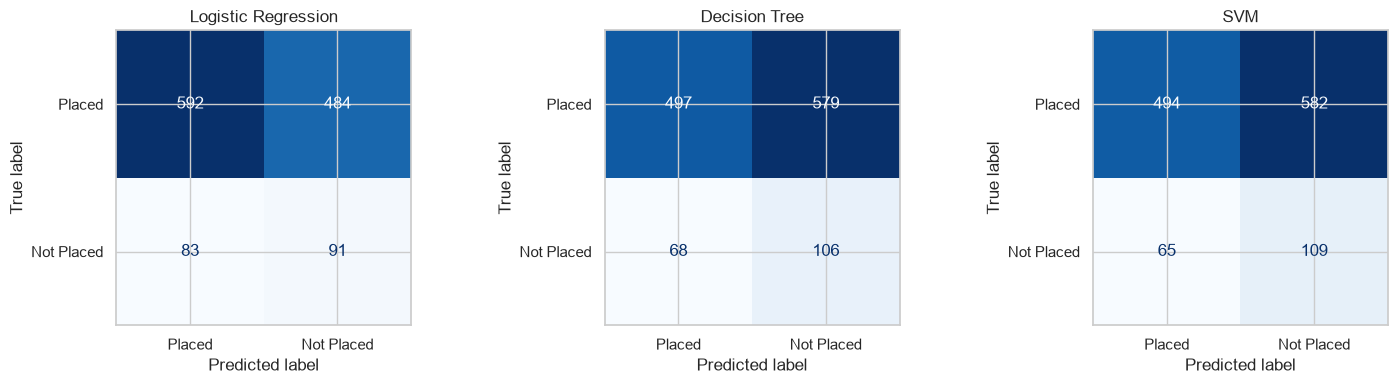

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for axis, (model_name, current_predictions) in zip(
    axes, model_predictions.items()
):
    matrix = confusion_matrix(
        y_test,
        current_predictions,
        labels=["Placed", "Not Placed"],
    )
    ConfusionMatrixDisplay(
        matrix,
        display_labels=["Placed", "Not Placed"],
    ).plot(ax=axis, cmap="Blues", colorbar=False)
    axis.set_title(model_name)

plt.tight_layout()
plt.show()

In [22]:
prediction_comparison = X_test.copy()
prediction_comparison["Actual"] = y_test

for model_name, current_predictions in model_predictions.items():
    prediction_comparison[model_name] = current_predictions

prediction_columns = list(model_predictions)
prediction_comparison["Models Agree"] = (
    prediction_comparison[prediction_columns].nunique(axis=1) == 1
)

print("Prediction agreement:")
display(prediction_comparison["Models Agree"].value_counts().rename(index={True: "Agree", False: "Disagree"}))

print("Examples where at least one model predicts differently:")
display(prediction_comparison.loc[~prediction_comparison["Models Agree"]].head(10))

Prediction agreement:


Models Agree
Agree       1003
Disagree     247
Name: count, dtype: int64

Examples where at least one model predicts differently:


,study_hours_per_day,Actual,Logistic Regression,Decision Tree,SVM,Models Agree
1793,6.1,Placed,Placed,Not Placed,Placed,False
2421,4.0,Placed,Placed,Not Placed,Not Placed,False
928,4.3,Placed,Placed,Placed,Not Placed,False
840,3.9,Placed,Placed,Not Placed,Not Placed,False
690,4.0,Placed,Placed,Not Placed,Not Placed,False
3182,0.6,Not Placed,Not Placed,Placed,Not Placed,False
302,4.1,Placed,Placed,Not Placed,Not Placed,False
3246,6.3,Placed,Placed,Not Placed,Placed,False
3614,6.3,Placed,Placed,Not Placed,Placed,False
3397,4.0,Not Placed,Placed,Not Placed,Not Placed,False


### Understanding disagreements and the tree

The confusion matrices show **what kind of mistakes** each model makes. The disagreement table goes one level deeper by showing the exact study-hour values where models produce different answers. Disagreement is expected because each algorithm learns differently:

- Logistic Regression changes probability smoothly as study hours change.
- A Decision Tree changes its prediction suddenly at learned split values.
- An RBF SVM can create several curved decision regions.

In the tree diagram:

- `entropy` measures class mixture; 0 means the node contains only one class;
- `samples` is the number of training examples reaching that node;
- `value` shows the weighted class counts;
- `class` is the prediction made at that node.

Start at the top and follow the left branch when a condition is true and the right branch when it is false. Continue until reaching a leaf.

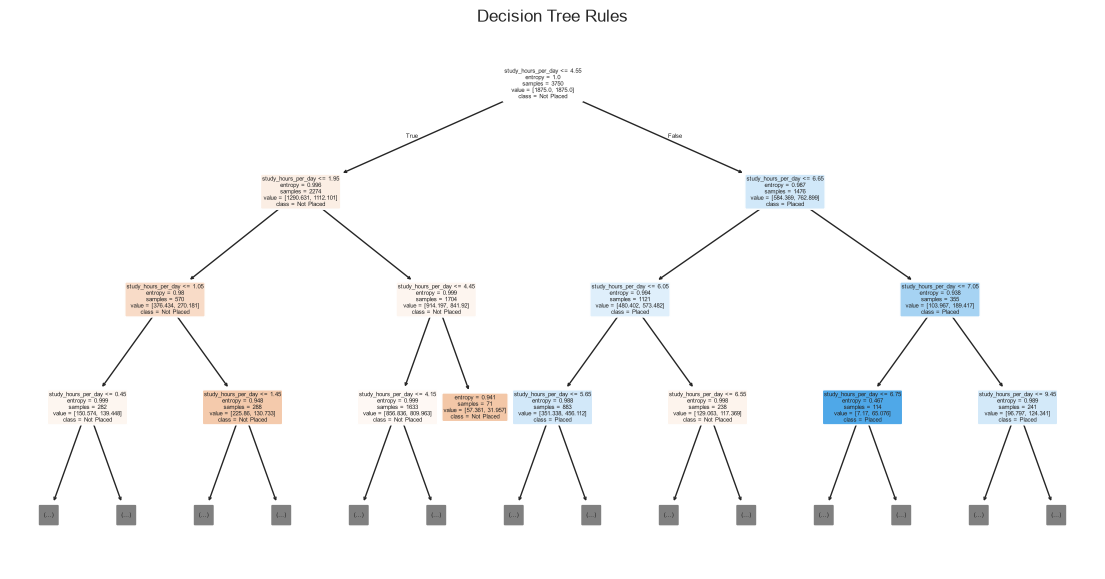

In [23]:
plt.figure(figsize=(14, 7))
plot_tree(
    decision_tree,
    feature_names=X.columns,
    class_names=decision_tree.classes_,
    filled=True,
    rounded=True,
    max_depth=3,
)
plt.title("Decision Tree Rules")
plt.show()

## 9. Cross-Validation and Hyperparameter Tuning

### Why one train/test split is not enough

A model's score can change depending on which rows happen to enter the test set. **Cross-validation (CV)** evaluates the model several times on different validation subsets, giving a more stable estimate.

In **5-fold cross-validation**, the training data is divided into five parts:

| Round | Fold 1 | Fold 2 | Fold 3 | Fold 4 | Fold 5 |
|---|---|---|---|---|---|
| 1 | Validation | Train | Train | Train | Train |
| 2 | Train | Validation | Train | Train | Train |
| 3 | Train | Train | Validation | Train | Train |
| 4 | Train | Train | Train | Validation | Train |
| 5 | Train | Train | Train | Train | Validation |

Every row is used for validation once and training four times. We report the **mean** score as typical performance and the **standard deviation** as stability across folds.

We use `StratifiedKFold` because this is classification. Stratification keeps approximately the same `Placed`/`Not Placed` ratio in each fold. `shuffle=True` randomizes rows, while `random_state=42` makes the folds reproducible.

### The most important leakage rule

Cross-validation and tuning use **only `X_train` and `y_train`**. The test set must remain untouched until one final evaluation. Selecting parameters using test scores would leak test information into model development and make the final result too optimistic.

### Parameters versus hyperparameters

- **Parameters** are learned from data, such as Logistic Regression coefficients or Decision Tree split thresholds.
- **Hyperparameters** are choices made before training, such as tree depth, SVM kernel, or regularization strength.

Cross-validation helps us choose hyperparameters without using the final test set.

In [31]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
placed_f1 = make_scorer(f1_score, pos_label="Placed", zero_division=0)
cv_scoring = {
    "accuracy": "accuracy",
    "placed_f1": placed_f1,
    "macro_f1": "f1_macro",
}

In [33]:
cv_strategy

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

In [24]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
placed_f1 = make_scorer(f1_score, pos_label="Placed", zero_division=0)
cv_scoring = {
    "accuracy": "accuracy",
    "placed_f1": placed_f1,
    "macro_f1": "f1_macro",
}

# Scaling is placed inside the SVM pipeline so each fold learns the scaler
# from its own training portion, preventing validation-data leakage.
cv_models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", solver="liblinear", random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4,
        criterion="entropy",
        class_weight="balanced",
        random_state=42,
    ),
    "SVM": Pipeline(
        [
            ("scaler", StandardScaler()),
            ("svc", SVC(class_weight="balanced")),
        ]
    ),
}

cv_rows = []
for model_name, model in cv_models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv_strategy,
        scoring=cv_scoring,
        return_train_score=True,
    )
    cv_rows.append(
        {
            "Model": model_name,
            "Mean Train Macro F1": scores["train_macro_f1"].mean(),
            "Mean CV Accuracy": scores["test_accuracy"].mean(),
            "Mean CV Placed F1": scores["test_placed_f1"].mean(),
            "Mean CV Macro F1": scores["test_macro_f1"].mean(),
            "CV Macro F1 Std": scores["test_macro_f1"].std(),
        }
    )

cv_summary = pd.DataFrame(cv_rows).set_index("Model").round(3)
display(cv_summary.sort_values("Mean CV Macro F1", ascending=False))

,Mean Train Macro F1,Mean CV Accuracy,Mean CV Placed F1,Mean CV Macro F1,CV Macro F1 Std
Model,,,,,
Logistic Regression,0.454,0.535,0.665,0.454,0.016
SVM,0.424,0.471,0.590,0.420,0.025
Decision Tree,0.428,0.464,0.576,0.413,0.047


### Reading the cross-validation table

- **Mean Train Macro F1** describes fit on the training portions of the folds.
- **Mean CV Placed F1** measures only the `Placed` class. It can look high when a model predicts the majority class very often.
- **Mean CV Macro F1** calculates F1 separately for `Placed` and `Not Placed`, then gives both classes equal importance. We use this for tuning.
- A much higher training Macro F1 than validation Macro F1 suggests **overfitting**.
- **CV Macro F1 Std** measures variation across folds. A smaller value means more stable results.

Cross-validation gives a stronger estimate than one split, but it does not improve a model by itself. We next use CV inside `GridSearchCV` to select hyperparameters.

### Decision Tree hyperparameters in depth

Tree hyperparameters control how easily the model can create rules:

- `criterion`: how split quality is measured. `gini` measures impurity; `entropy` uses information gain.
- `max_depth`: maximum number of levels. Small values may underfit; very large values may overfit.
- `min_samples_split`: minimum examples needed to split a node. Larger values prevent rules based on tiny groups.
- `min_samples_leaf`: minimum examples allowed in a final leaf. Larger leaves create smoother, more reliable rules.
- `ccp_alpha`: pruning strength. Larger values remove weak branches after the tree is built.
- `class_weight`: controls the importance of each class; `balanced` automatically compensates for imbalance.

These controls represent a **bias-variance trade-off**:

- an overly simple tree has high bias and underfits;
- an overly complex tree has high variance and overfits;
- cross-validation searches for a useful balance.

`GridSearchCV` trains every parameter combination across all five folds. We optimize **Macro F1**, not accuracy or majority-class F1, because the target is imbalanced and performance on both classes matters.

In [35]:
tree_param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [2, 3, 4, 6, None],
    "min_samples_split": [2, 20, 50],
    "min_samples_leaf": [1, 10, 25],
    "ccp_alpha": [0.0, 0.001],
}
tree_param_grid

{'criterion': ['gini', 'entropy'],
 'max_depth': [2, 3, 4, 6, None],
 'min_samples_split': [2, 20, 50],
 'min_samples_leaf': [1, 10, 25],
 'ccp_alpha': [0.0, 0.001]}

In [57]:
cv_strategy_1 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 2 x 5 x 3 x 3 x 2 = 180 candidates; each is evaluated on 5 folds.
tree_search = GridSearchCV(   
    estimator=DecisionTreeClassifier( class_weight="balanced",random_state=42),  #MODEL NAME
    param_grid=tree_param_grid,  # hyper_parameters
    scoring="f1_macro",
    cv=cv_strategy_1,
    n_jobs=-1,
    return_train_score=True,
)

In [48]:
from sklearn.linear_model import LinearRegression


LinearRegression()

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [45]:
tree_search

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'ccp_alpha': [0.0, 0.001], 'criterion': ['gini', 'entropy'], 'max_depth': [2, 3, ...], 'min_samples_leaf': [1, 10, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will on

In [58]:
tree_search.fit(X_train, y_train)

print("Best Decision Tree parameters:")
print(tree_search.best_params_)
print(f"Best mean CV Macro F1: {tree_search.best_score_:.3f}")

Best Decision Tree parameters:
{'ccp_alpha': 0.0, 'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 25, 'min_samples_split': 2}
Best mean CV Macro F1: 0.452


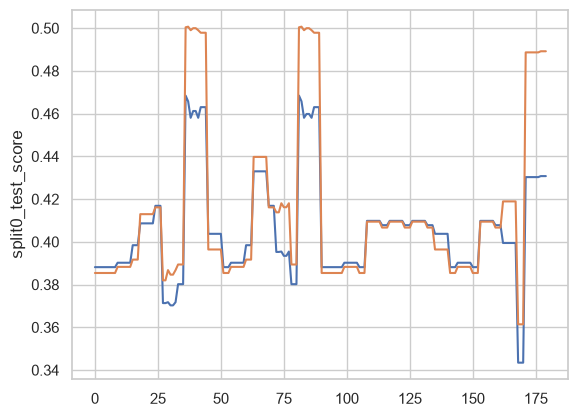

In [62]:
import seaborn as sns

tree_cv_results = pd.DataFrame(tree_search.cv_results_)
tree_cv_results[['split0_test_score', "split0_train_score" ]]

sns.lineplot(tree_cv_results['split0_test_score'])
sns.lineplot(tree_cv_results['split0_train_score'])
plt.show()

In [72]:
tree_cv_results[tree_cv_results['split0_test_score'] > 0.45]['params']

36    {'ccp_alpha': 0.0, 'criterion': 'gini', 'max_d...
37    {'ccp_alpha': 0.0, 'criterion': 'gini', 'max_d...
38    {'ccp_alpha': 0.0, 'criterion': 'gini', 'max_d...
39    {'ccp_alpha': 0.0, 'criterion': 'gini', 'max_d...
40    {'ccp_alpha': 0.0, 'criterion': 'gini', 'max_d...
41    {'ccp_alpha': 0.0, 'criterion': 'gini', 'max_d...
42    {'ccp_alpha': 0.0, 'criterion': 'gini', 'max_d...
43    {'ccp_alpha': 0.0, 'criterion': 'gini', 'max_d...
44    {'ccp_alpha': 0.0, 'criterion': 'gini', 'max_d...
81    {'ccp_alpha': 0.0, 'criterion': 'entropy', 'ma...
82    {'ccp_alpha': 0.0, 'criterion': 'entropy', 'ma...
83    {'ccp_alpha': 0.0, 'criterion': 'entropy', 'ma...
84    {'ccp_alpha': 0.0, 'criterion': 'entropy', 'ma...
85    {'ccp_alpha': 0.0, 'criterion': 'entropy', 'ma...
86    {'ccp_alpha': 0.0, 'criterion': 'entropy', 'ma...
87    {'ccp_alpha': 0.0, 'criterion': 'entropy', 'ma...
88    {'ccp_alpha': 0.0, 'criterion': 'entropy', 'ma...
89    {'ccp_alpha': 0.0, 'criterion': 'entropy',

In [26]:
tree_cv_results = pd.DataFrame(tree_search.cv_results_)
tree_cv_results["train_validation_gap"] = (
    tree_cv_results["mean_train_score"] - tree_cv_results["mean_test_score"]
)

result_columns = [
    "param_criterion",
    "param_max_depth",
    "param_min_samples_split",
    "param_min_samples_leaf",
    "param_ccp_alpha",
    "mean_train_score",
    "mean_test_score",
    "std_test_score",
    "train_validation_gap",
]

print("Top five Decision Tree configurations by mean CV F1:")
display(
    tree_cv_results.sort_values("rank_test_score")[result_columns]
    .head()
    .round(3)
)

Top five Decision Tree configurations by mean CV F1:


,param_criterion,param_max_depth,param_min_samples_split,param_min_samples_leaf,param_ccp_alpha,mean_train_score,mean_test_score,std_test_score,train_validation_gap
44,gini,None,50,25,0.0,0.494,0.452,0.018,0.041
43,gini,None,20,25,0.0,0.494,0.452,0.018,0.041
42,gini,None,2,25,0.0,0.494,0.452,0.018,0.041
88,entropy,None,20,25,0.0,0.494,0.452,0.018,0.041
89,entropy,None,50,25,0.0,0.494,0.452,0.018,0.041


### Tuning Logistic Regression and SVM

For Logistic Regression:

- `C` controls regularization. A small `C` applies stronger regularization and keeps coefficients smaller; a large `C` allows a more flexible fit.
- `class_weight` compares ordinary training with automatic class balancing.

For SVM:

- `kernel="linear"` creates a straight decision boundary.
- `kernel="rbf"` allows a nonlinear boundary.
- `C` controls the penalty for classification errors. Larger values try harder to classify training examples correctly and may overfit.
- `gamma` controls how local the influence of each example is for the RBF kernel. Large values create more detailed boundaries and may overfit.

Both searches use a `Pipeline`. `StandardScaler` is fitted separately within each training fold, so information from the validation fold cannot influence scaling.

In [27]:
logistic_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        (
            "model",
            LogisticRegression(solver="liblinear", random_state=42),
        ),
    ]
)
logistic_param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"],
}

logistic_search = GridSearchCV(
    logistic_pipeline,
    logistic_param_grid,
    scoring="f1_macro",
    cv=cv_strategy,
    n_jobs=-1,
)
logistic_search.fit(X_train, y_train)

print("Best Logistic Regression parameters:")
print(logistic_search.best_params_)
print(f"Best mean CV Macro F1: {logistic_search.best_score_:.3f}")

Best Logistic Regression parameters:
{'model__C': 0.01, 'model__class_weight': None}
Best mean CV Macro F1: 0.463


In [28]:
svm_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("model", SVC(class_weight="balanced")),
    ]
)

# Separate dictionaries avoid testing gamma when the linear kernel ignores it.
svm_param_grid = [
    {
        "model__kernel": ["linear"],
        "model__C": [0.1, 1, 10, 100],
    },
    {
        "model__kernel": ["rbf"],
        "model__C": [0.1, 1, 10, 100],
        "model__gamma": ["scale", 0.1, 1],
    },
]

svm_search = GridSearchCV(
    svm_pipeline,
    svm_param_grid,
    scoring="f1_macro",
    cv=cv_strategy,
    n_jobs=-1,
)
svm_search.fit(X_train, y_train)

print("Best SVM parameters:")
print(svm_search.best_params_)
print(f"Best mean CV Macro F1: {svm_search.best_score_:.3f}")

Best SVM parameters:
{'model__C': 0.1, 'model__kernel': 'linear'}
Best mean CV Macro F1: 0.457


### Final evaluation on the untouched test set

`best_estimator_` is automatically refitted on the complete training set using the winning hyperparameters. Only now do we evaluate each tuned model on `X_test` and `y_test`.

- **Best CV Macro F1** was used to select hyperparameters and treats both classes equally.
- **Test Macro F1** is the main final balanced metric on unseen test rows.
- **Placed F1**, precision, and recall retain the original positive-class view for comparison.

CV and test scores will not be identical because they use different rows. We must not return to tuning after repeatedly inspecting test results; doing so would gradually overfit our choices to the test set.

,Best CV Macro F1,Test Macro F1,Accuracy,Precision,Recall,Placed F1
Model,,,,,,
Tuned Logistic Regression,0.463,0.463,0.861,0.861,1.000,0.925
Tuned Decision Tree,0.452,0.462,0.568,0.868,0.587,0.701
Tuned SVM,0.457,0.460,0.546,0.877,0.550,0.676


,Untuned Test Macro F1,Tuned Test Macro F1,Macro F1 Change
Logistic Regression,0.460,0.463,0.003
Decision Tree,0.426,0.462,0.036
SVM,0.428,0.460,0.032


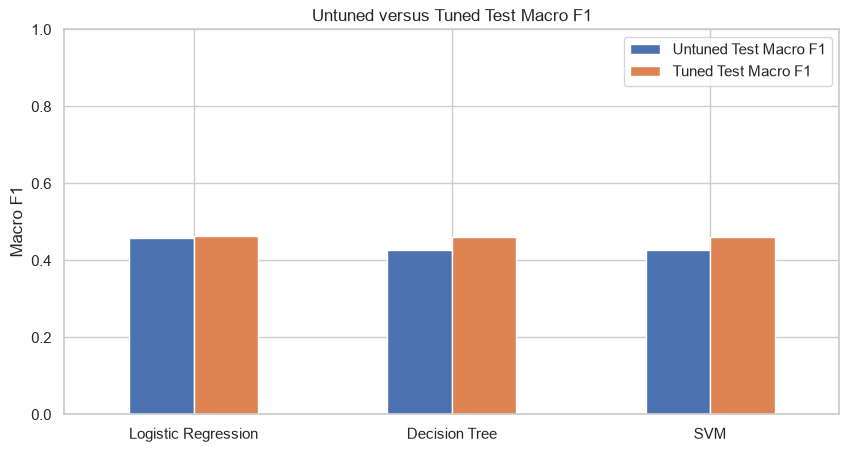

In [29]:
tuned_searches = {
    "Tuned Logistic Regression": logistic_search,
    "Tuned Decision Tree": tree_search,
    "Tuned SVM": svm_search,
}

tuned_rows = []
for model_name, search in tuned_searches.items():
    tuned_predictions = search.best_estimator_.predict(X_test)
    model_result = evaluate_model(model_name, y_test, tuned_predictions)
    model_result["Best CV Macro F1"] = search.best_score_
    model_result["Test Macro F1"] = f1_score(
        y_test,
        tuned_predictions,
        average="macro",
        zero_division=0,
    )
    tuned_rows.append(model_result)

tuned_comparison = pd.DataFrame(tuned_rows).set_index("Model")
tuned_comparison = tuned_comparison[
    [
        "Best CV Macro F1",
        "Test Macro F1",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
    ]
].rename(columns={"F1 Score": "Placed F1"}).round(3)

display(tuned_comparison.sort_values("Test Macro F1", ascending=False))

untuned_macro_f1 = {
    model_name: f1_score(
        y_test,
        current_predictions,
        average="macro",
        zero_division=0,
    )
    for model_name, current_predictions in model_predictions.items()
}
before_after = pd.DataFrame(
    {
        "Untuned Test Macro F1": pd.Series(untuned_macro_f1),
        "Tuned Test Macro F1": [
            tuned_comparison.loc["Tuned Logistic Regression", "Test Macro F1"],
            tuned_comparison.loc["Tuned Decision Tree", "Test Macro F1"],
            tuned_comparison.loc["Tuned SVM", "Test Macro F1"],
        ],
    },
    index=["Logistic Regression", "Decision Tree", "SVM"],
)
before_after["Macro F1 Change"] = (
    before_after["Tuned Test Macro F1"]
    - before_after["Untuned Test Macro F1"]
)

display(before_after.round(3))
before_after[["Untuned Test Macro F1", "Tuned Test Macro F1"]].plot(
    kind="bar", ylim=(0, 1), figsize=(10, 5)
)
plt.title("Untuned versus Tuned Test Macro F1")
plt.ylabel("Macro F1")
plt.xlabel("")
plt.xticks(rotation=0)
plt.show()

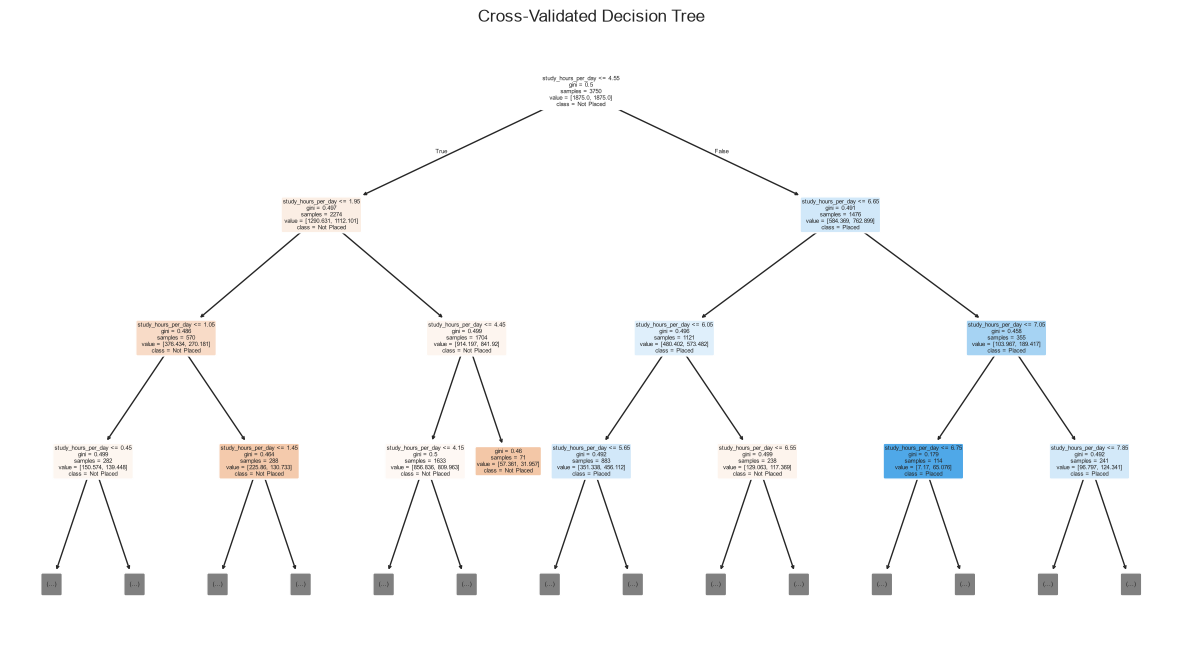

Selected tree depth: 14
Selected number of leaves: 70


In [30]:
best_tree = tree_search.best_estimator_

plt.figure(figsize=(15, 8))
plot_tree(
    best_tree,
    feature_names=X.columns,
    class_names=best_tree.classes_,
    filled=True,
    rounded=True,
    max_depth=3,
)
plt.title("Cross-Validated Decision Tree")
plt.show()

print("Selected tree depth:", best_tree.get_depth())
print("Selected number of leaves:", best_tree.get_n_leaves())

### Interpreting the tuned results

For this fixed dataset and split:

- **Tuned Logistic Regression** has Test Macro F1 `0.463`. Its recall for `Placed` is `1.000` because it predicts every test student as `Placed`. The high accuracy (`0.861`) and Placed F1 (`0.925`) mainly reflect the majority class, not strong separation of both classes.
- **Tuned Decision Tree** has Test Macro F1 `0.462`, an improvement of `0.036` over its untuned result. CV selected `min_samples_leaf=25`, which prevents tiny leaves, while allowing the tree to grow until other constraints stop it.
- **Tuned SVM** has Test Macro F1 `0.460`, an improvement of `0.032`. CV selected a linear kernel with `C=0.1`, favoring a simpler boundary.

The three tuned models have very similar Macro F1 scores. Differences this small should not be treated as proof that one algorithm is universally superior. More informative features are likely more valuable than further tuning of a one-feature model.

The Logistic Regression example also demonstrates an essential lesson: **the metric used for selection shapes the chosen model**. Even Macro F1 can select a majority predictor when the available feature has little ability to separate the classes. Always inspect per-class metrics and confusion matrices alongside the optimization score.

## 10. Key takeaways

- Classification predicts categories; here the categories are `Placed` and `Not Placed`.
- Logistic Regression learns a smooth probability curve and is easy to interpret.
- A Decision Tree learns if/else rules; depth, leaf size, split size, and pruning control its complexity.
- An SVM finds a wide-margin boundary; `C`, `gamma`, and the kernel control its behavior.
- One train/test split may give a noisy estimate; stratified cross-validation repeats validation across balanced folds.
- Mean CV score estimates typical performance, while CV standard deviation describes stability.
- For imbalanced targets, Macro F1 gives each class equal importance; majority-class F1 alone can be misleading.
- Hyperparameters must be selected using training data and validation folds, never the final test set.
- Pipelines prevent preprocessing leakage by fitting transformations separately inside each fold.
- `GridSearchCV` compares specified combinations; it cannot discover values outside the parameter grid.
- Tuning does not guarantee a higher test score. Its purpose is principled model selection without using test labels.
- A single feature makes the lesson easy to visualize, but it cannot describe the full placement process.

## Practice exercises

1. Change `n_splits` from 5 to 3 and 10. How do mean CV Macro F1, standard deviation, and runtime change?
2. Change GridSearchCV scoring from `"f1_macro"` to `"accuracy"`. Do the selected parameters change? Why?
3. Plot Decision Tree mean training Macro F1 and mean CV Macro F1 for each `max_depth`. Identify underfitting and overfitting regions.
4. Add `ccp_alpha` values `0.005` and `0.01`. How do tree depth, leaf count, and Macro F1 change?
5. Compare `min_samples_leaf=1` with larger values. Why can larger leaves improve stability?
6. Try `kernel="poly"` for SVM and add suitable `degree` values. Compare CV Macro F1 and runtime.
7. Expand Logistic Regression `C` values using `np.logspace(-4, 4, 9)`. Which region performs best?
8. Add CGPA, coding skill, communication skill, projects, and internships. Keep scaling inside the pipeline and rerun all searches.
9. Explain why tuning on `X_test` would be data leakage.
10. Replace `GridSearchCV` with `RandomizedSearchCV` for a larger search space. Compare search time and results.

> In a real project, document the search space before examining test results, use cross-validation for model selection, and evaluate the chosen model on the test set only once.